<a href="https://colab.research.google.com/github/sachitsaz/Computer-Vision/blob/main/3D-CV/01_Depth_Anything/cv_05_2_DepthAnything_V2_small.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

In [ ]:
!pip install -q transformers accelerate

In [ ]:
dataset_path = "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs"

image_path = os.path.join(
    dataset_path,
    "image_01.png"
)

gt_depth_path = os.path.join(
    dataset_path,
    "depth_01.npy"
)

print(image_path)
print(gt_depth_path)

/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/image_01.png
/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/depth_01.npy


Image size: (561, 427)


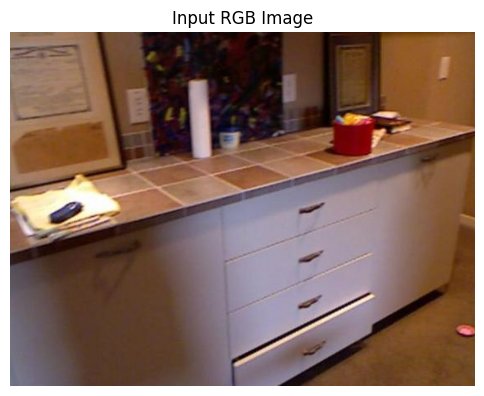

In [ ]:
# Load your Depth8 image
image = Image.open(image_path).convert("RGB")

print("Image size:", image.size)

plt.figure(figsize=(6,5))
plt.imshow(image)
plt.title("Input RGB Image")
plt.axis("off")
plt.show()

In [ ]:
# Load Depth Anything V3
model_name = "depth-anything/Depth-Anything-V2-Small-hf"


processor = AutoImageProcessor.from_pretrained(
    model_name
)

model = AutoModelForDepthEstimation.from_pretrained(
    model_name
)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)
model.eval()

print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Device: cpu


In [ ]:
# Run inference
inputs = processor(
    images=image,
    return_tensors="pt"
)


inputs = {
    k: v.to(device)
    for k,v in inputs.items()
}


with torch.no_grad():
    outputs = model(**inputs)


predicted_depth = outputs.predicted_depth


print(predicted_depth.shape)

torch.Size([1, 392, 518])


The Depth Anything model does not necessarily operate on the original image resolution. The input image is first resized by the preprocessing module to match the model's required input dimensions. The model generates a depth map with the same spatial dimensions as this processed input. The predicted depth map is then resized back to the original image resolution so that it can be visualized alongside the RGB image or compared pixel-wise with the ground-truth depth map.

In [ ]:
# Resize to original image size
depth = predicted_depth.unsqueeze(1)


depth = F.interpolate(
    depth,
    size=image.size[::-1],
    mode="bicubic",
    align_corners=False
)


depth = depth.squeeze().cpu().numpy()


print(depth.shape)
print(depth.dtype)

(427, 561)
float32


| Stage                   | Size          |
| ----------------------- | ------------- |
| Original RGB image      | 427 × 561 × 3 |
| Model input             | 392 × 518 × 3 |
| Raw model output        | 392 × 518     |
| Final resized depth map | 427 × 561     |


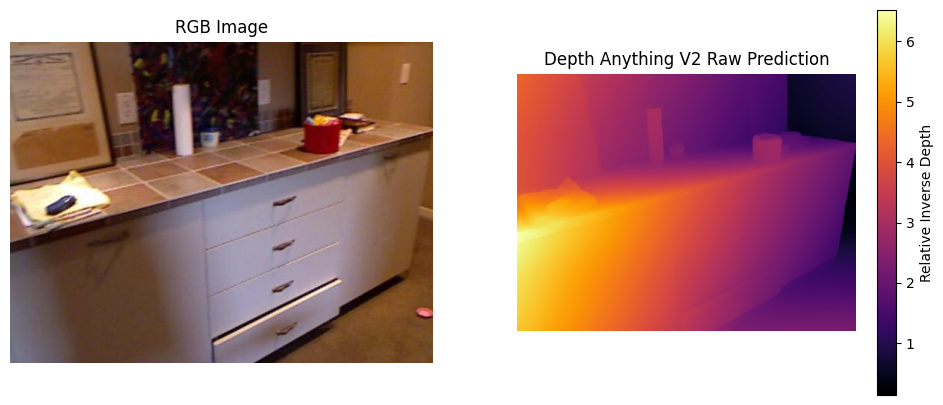

In [ ]:
# Display RGB and predicted depth
plt.figure(figsize=(12,5))


plt.subplot(1,2,1)
plt.imshow(image)
plt.title("RGB Image")
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(depth, cmap="inferno")
plt.title("Depth Anything V2 Raw Prediction")
plt.colorbar(label = "Relative Inverse Depth" )
plt.axis("off")


plt.show()

In [ ]:
print(depth.min())
print(depth.max())
print(depth.mean())

0.14241537
6.5203133
3.1419258


low values  → dark purple

high values → yellow

dark purple = smaller numerical value

yellow      = larger numerical value

Depth Anything V2 (the model we are using) produces relative depth.

However, many monocular depth models internally learn a representation closer to inverse depth:

inverse depth = 1/ditance

Meaning:

* nearby objects → larger value
* far objects → smaller value

For example:

Object A:
Distance = 1 meter

inverse depth = 1/1 = 1.0


Object B:
Distance = 5 meters

inverse depth = 1/5 = 0.2

Therefore:

near object → high value → yellow

far object  → low value → purple

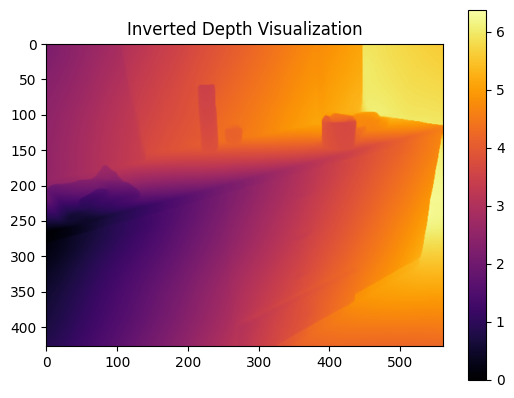

In [ ]:
# Better intuition
depth_vis = depth.max() - depth

plt.imshow(depth_vis, cmap="inferno")
plt.colorbar()
plt.title("Inverted Depth Visualization")
plt.show()

In [ ]:
gt_depth = np.load(
    "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/depth_01.npy"
)

print("Ground truth:")
print("shape:", gt_depth.shape)
print("dtype:", gt_depth.dtype)
print("min:", gt_depth.min())
print("max:", gt_depth.max())

Ground truth:
shape: (427, 561)
dtype: float32
min: 0.963
max: 3.08


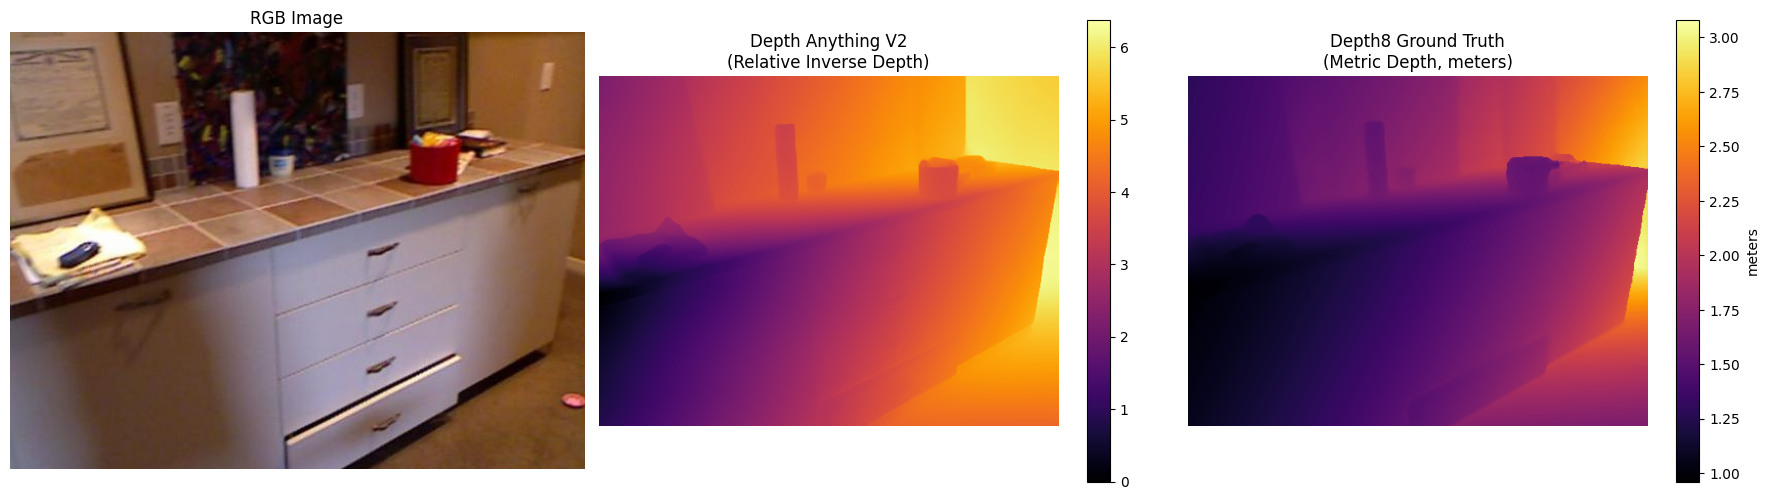

In [ ]:
plt.figure(figsize=(18,5))


plt.subplot(1,3,1)
plt.imshow(image)
plt.title("RGB Image")
plt.axis("off")


depth_vis = depth.max() - depth
plt.subplot(1,3,2)
plt.imshow(depth_vis, cmap="inferno")
plt.colorbar()
plt.title("Depth Anything V2\n(Relative Inverse Depth)")
plt.axis("off")


plt.subplot(1,3,3)
plt.imshow(gt_depth, cmap="inferno")
plt.title("Depth8 Ground Truth\n(Metric Depth, meters)")
plt.colorbar(label="meters")
plt.axis("off")


plt.tight_layout()
plt.show()

The ground-truth depth map provides **metric distance** values in **meters**, while the Depth Anything output represents **relative depth**. Therefore, direct numerical comparison is not meaningful without scale alignment. However, the two depth maps can be compared visually to evaluate whether the model correctly captures the relative geometry of the scene.

In [ ]:
# Save Depth Map as an image
output_path = "/content/drive/MyDrive/Computer Vision/05/Predicted_depths/predicted_depth_01.png"


plt.figure(figsize=(8,6))

plt.imshow(
    depth,
    cmap="inferno"
)

plt.axis("off")

plt.colorbar(
    label="Relative Depth"
)

plt.savefig(
    output_path,
    bbox_inches="tight",
    dpi=300
)

plt.close()


print("Saved:", output_path)

Saved: /content/drive/MyDrive/Computer Vision/05/Predicted_depths/predicted_depth_01.png


In [ ]:
# Save Depth Map as NumPy array
depth_array_path = "/content/drive/MyDrive/Computer Vision/05/Predicted_depths/predicted_depth_01.npy"

np.save(
    depth_array_path,
    depth
)

print("NumPy depth array saved:")
print(depth_array_path)

NumPy depth array saved:
/content/drive/MyDrive/Computer Vision/05/Predicted_depths/predicted_depth_01.npy


This continuation will:
* calculate depth.shape, dtype, min, max, mean, std
* find pixels with minimum and maximum depth
* calculate center pixel depth
* plot histogram
* save depth as NumPy array
* prepare values for the analysis question

In [ ]:
# Load previously saved predicted depth array

predicted_depth_path = "/content/drive/MyDrive/Computer Vision/05/Predicted_depths/predicted_depth_01.npy"

depth = np.load(
    predicted_depth_path,
    allow_pickle=False
)

print("Loaded depth map successfully")
print("Shape:", depth.shape)
print("dtype:", depth.dtype)
print("min:", depth.min())
print("max:", depth.max())
print("mean:", depth.mean())

Loaded depth map successfully
Shape: (427, 561)
dtype: float32
min: 0.14241537
max: 6.5203133
mean: 3.1419258


Depth shape: (427, 561)
Depth dtype: float32
Minimum depth value: 0.14241537
Maximum depth value: 6.5203133
Mean depth value: 3.1419258
Standard deviation: 1.3730483

Pixel with minimum depth:
Coordinates (row, column): (np.int64(234), np.int64(542))
Depth value: 0.14241537

Pixel with maximum depth:
Coordinates (row, column): (np.int64(267), np.int64(0))
Depth value: 6.5203133

Center pixel:
Coordinates (row, column): (213, 280)
Depth value: 4.118167


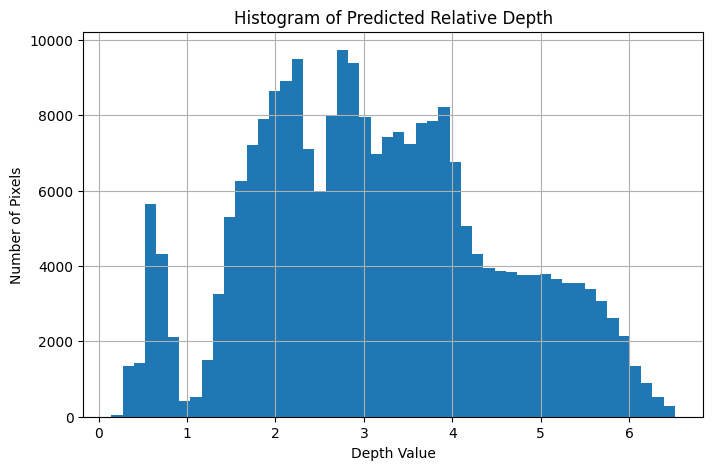


Loaded depth array:
Shape: (427, 561)
dtype: float32


In [ ]:
# Basic depth statistics

print("Depth shape:", depth.shape)
print("Depth dtype:", depth.dtype)

print("Minimum depth value:", depth.min())
print("Maximum depth value:", depth.max())
print("Mean depth value:", depth.mean())
print("Standard deviation:", depth.std())


# ------------------------------------------
# Pixel coordinates with minimum depth
# ------------------------------------------

min_index = np.unravel_index(
    np.argmin(depth),
    depth.shape
)

print("\nPixel with minimum depth:")
print("Coordinates (row, column):", min_index)
print("Depth value:", depth[min_index])


# ------------------------------------------
# Pixel coordinates with maximum depth
# ------------------------------------------

max_index = np.unravel_index(
    np.argmax(depth),
    depth.shape
)

print("\nPixel with maximum depth:")
print("Coordinates (row, column):", max_index)
print("Depth value:", depth[max_index])


# ------------------------------------------
# Depth value at image center
# ------------------------------------------

height, width = depth.shape

center_y = height // 2
center_x = width // 2

center_depth = depth[center_y, center_x]

print("\nCenter pixel:")
print("Coordinates (row, column):", (center_y, center_x))
print("Depth value:", center_depth)


# ------------------------------------------
# Depth histogram
# ------------------------------------------

plt.figure(figsize=(8,5))

plt.hist(
    depth.flatten(),
    bins=50
)

plt.xlabel("Depth Value")
plt.ylabel("Number of Pixels")
plt.title("Histogram of Predicted Relative Depth")

plt.grid(True)

plt.show()


# ------------------------------------------
# Depth Map as NumPy array
# ------------------------------------------

depth_array_path = "/content/drive/MyDrive/Computer Vision/05/Predicted_depths/predicted_depth_01.npy"


# Verify saved file
loaded_depth = np.load(depth_array_path)

print("\nLoaded depth array:")
print("Shape:", loaded_depth.shape)
print("dtype:", loaded_depth.dtype)